# 03 — Reception predictor (W3)

LightGBM on catalog **launch** metadata → positive-review-ratio bucket
(`negative_or_mixed` < 70% ≤ `mostly_positive` < 80% ≤ `very_positive`, Steam's own label
boundaries; games with ≥ 50 votes). Time-based split: train 2014–2021, early stopping on 2022,
test on releases from 2023. Post-launch fields (owners, CCU, playtime, Metacritic, DLC count,
achievements, Trading Cards) and evaluative tags ("Great Soundtrack", "Classic", …) are
excluded. Same code as `sga train reception`; this notebook writes `models/`.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from steam_game_analyst.config import get_settings
from steam_game_analyst.ml import reception as rc

s = get_settings()
games_all = pl.read_parquet(s.processed_dir / "games_all.parquet")
model, metrics = rc.train(games_all, seed=13)
rc.save(model, metrics, s.models_dir)
print(json.dumps({k: metrics[k] for k in ("n", "class_share", "best_iteration", "n_features")}, indent=1))

{
 "n": {
  "train": 18692,
  "valid": 2411,
  "test": 7368
 },
 "class_share": {
  "train": [
   0.2914080890220415,
   0.20907340038519154,
   0.499518510592767
  ],
  "valid": [
   0.1936955620074658,
   0.1883036084612194,
   0.6180008295313149
  ],
  "test": [
   0.1492942453854506,
   0.18390336590662323,
   0.6668023887079262
  ]
 },
 "best_iteration": 208,
 "n_features": 272
}


Very positive games become more common every year, so the test years have a larger
majority class than the training years: this drift is why the split is by date.

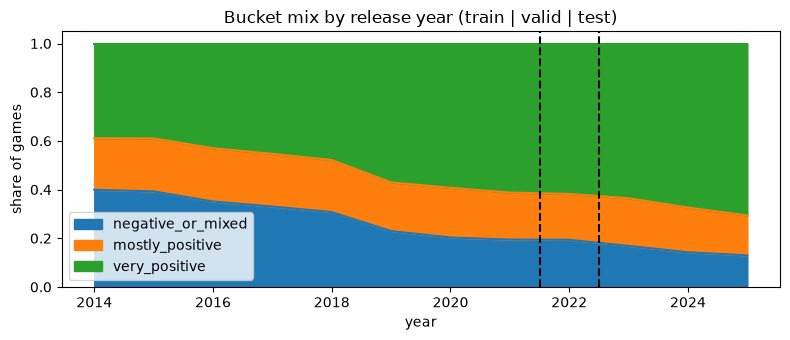

In [2]:
lab = rc.labelled_games(games_all).filter(pl.col("release_date") >= rc.TRAIN_FROM)
share = (lab.group_by(pl.col("release_date").dt.year().alias("year"), "bucket").len()
         .with_columns((pl.col("len") / pl.col("len").sum().over("year")).alias("share"))
         .pivot(on="bucket", index="year", values="share").sort("year"))
ax = share.to_pandas().set_index("year")[["0", "1", "2"]].rename(columns={str(i): b for i, b in enumerate(rc.BUCKETS)}).plot.area(figsize=(8, 3.5))
ax.axvline(2021.5, color="k", ls="--"); ax.axvline(2022.5, color="k", ls="--")
ax.set_ylabel("share of games"); ax.set_title("Bucket mix by release year (train | valid | test)")
plt.tight_layout()

In [3]:
cols = ["accuracy", "accuracy_ci95", "accuracy_gain_vs_majority_ci95", "macro_f1", "log_loss", "brier", "ece"]
t, b = metrics["test"], metrics["majority_baseline"]
pl.DataFrame([{"model": "LightGBM", **{c: str(t.get(c)) for c in cols}},
              {"model": f"majority ({b['predicts']})", **{c: str(b.get(c, "")) for c in cols}}])

model,accuracy,accuracy_ci95,accuracy_gain_vs_majority_ci95,macro_f1,log_loss,brier,ece
str,str,str,str,str,str,str,str
"""LightGBM""","""0.6737242128121607""","""[0.6628664495114006, 0.6843105…","""[-0.0008143322475570036, 0.014…","""0.42386378801886737""","""0.7790089654964779""","""0.44630513456765863""","""0.01525065370246178"""
"""majority (very_positive)""","""0.6668023887079262""","""""","""""","""0.2666992373042369""","""0.9347406193503124""","""0.5480791257824723""","""0.16728387811515905"""


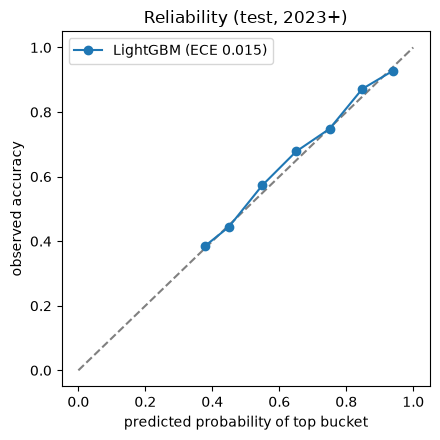

In [4]:
rel = pl.DataFrame(metrics["test"]["reliability"])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(rel["mean_confidence"], rel["accuracy"], "o-", label=f"LightGBM (ECE {t['ece']:.3f})")
ax.set_xlabel("predicted probability of top bucket"); ax.set_ylabel("observed accuracy")
ax.set_title("Reliability (test, 2023+)"); ax.legend(); plt.tight_layout()

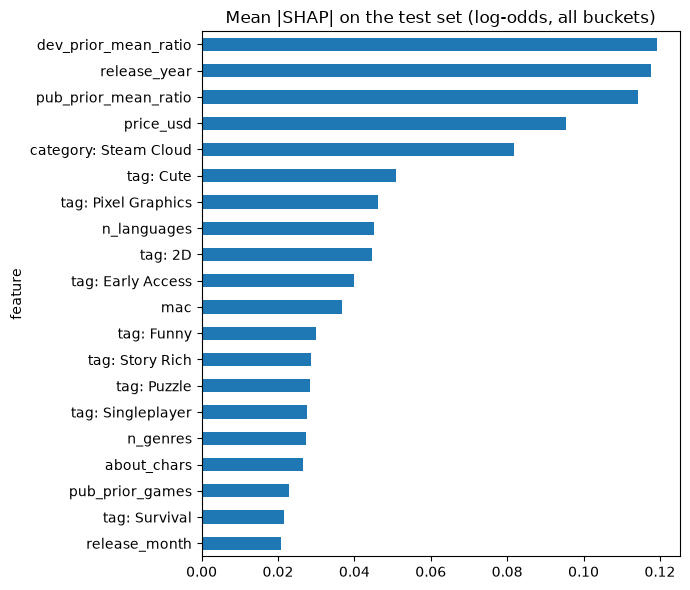

In [5]:
imp = pl.DataFrame({"feature": list(metrics["shap_mean_abs_top20"]),
                    "mean_abs_shap": list(metrics["shap_mean_abs_top20"].values())})
imp.to_pandas().set_index("feature").iloc[::-1].plot.barh(figsize=(7, 6), legend=False,
    title="Mean |SHAP| on the test set (log-odds, all buckets)")
plt.tight_layout()

## Example: a hypothetical launch

In [6]:
from datetime import date
spec = rc.GameSpec(price_usd=14.99, tags=["Puzzle", "Relaxing", "Cute"], genres=["Casual", "Indie"],
                   release_date=date(2026, 11, 1))
model.predict(spec)

{'bucket': 'very_positive',
 'probabilities': {'negative_or_mixed': 0.181,
  'mostly_positive': 0.1085,
  'very_positive': 0.7104},
 'top_features': [{'feature': 'tag: Cute',
   'value': 1.0,
   'shap': 0.3387,
   'pushes': 'towards'},
  {'feature': 'tag: Relaxing',
   'value': 1.0,
   'shap': 0.1574,
   'pushes': 'towards'},
  {'feature': 'tag: Puzzle',
   'value': 1.0,
   'shap': 0.1467,
   'pushes': 'towards'},
  {'feature': 'release_year',
   'value': 2026.0,
   'shap': 0.1352,
   'pushes': 'towards'},
  {'feature': 'price_usd',
   'value': 14.99,
   'shap': 0.1034,
   'pushes': 'towards'},
  {'feature': 'category: Single-player',
   'value': 0.0,
   'shap': -0.0835,
   'pushes': 'away from'},
  {'feature': 'tag: 2D', 'value': 0.0, 'shap': -0.073, 'pushes': 'away from'},
  {'feature': 'n_languages',
   'value': 2.0,
   'shap': -0.0632,
   'pushes': 'away from'}],
 'inputs_used': {'release_date': '2026-11-01',
  'tags': ['Puzzle', 'Relaxing', 'Cute'],
  'genres': ['Casual', 'Indie']